# 05 · Models - can we spot single-bid tenders before they happen?

## Step 1 · Load the clue table and extra columns

In [1]:
# pandas = tables, numpy = maths helpers
import pandas as pd
import numpy as np

In [2]:
# matplotlib = charts, os = folders
import matplotlib.pyplot as plt
import os

In [3]:
# Let Python look one folder up, where tenderlens_style.py lives
import sys
sys.path.append("..")

In [4]:
# My colours and chart helpers with the short name ts
import tenderlens_style as ts

In [5]:
# Model 1: Logistic Regression (a simple weighted score)
from sklearn.linear_model import LogisticRegression

In [6]:
# Model 2: Random Forest (many decision trees that vote)
from sklearn.ensemble import RandomForestClassifier

In [7]:
# Model 3: XGBoost (trees built one after another, each fixing earlier mistakes)
from xgboost import XGBClassifier

In [8]:
# Scaler = puts all clues on the same size scale (needed for Logistic Regression)
from sklearn.preprocessing import StandardScaler

In [9]:
# Two scores: PR-AUC (average_precision_score) and ROC-AUC (roc_auc_score)
from sklearn.metrics import average_precision_score
from sklearn.metrics import roc_auc_score

In [10]:
# The clue table from S4 (one row = one labelled tender)
lab = pd.read_csv("../data/processed/features_split.csv", parse_dates=["published_date"])
lab.shape

(6790, 17)

In [11]:
# The full clean table from S2 (all 39,411 tenders)
df = pd.read_csv("../data/interim/tenders_clean.csv", parse_dates=["published_date"])
df.shape

(39411, 39)

In [12]:
# How many times did the same department post the same title BEFORE this tender?
# The table is in date order, so cumcount gives 0 for the first time, 1 for the second, ...
df["times_before"] = df.groupby(["dept_main", "title_key"]).cumcount()

In [13]:
# Extra columns we want in lab (all are known on the day the tender is published,
# except number_of_bids, which we use ONLY for checks, never as a clue)
extra = ["tender_id", "category", "contract_form", "product_category", "tender_type",
         "emd_amount", "tender_fee", "work_period_days", "times_before", "title_key", "number_of_bids"]

In [14]:
# Glue the extra columns onto lab by matching tender_id (left = keep every lab row)
lab = lab.merge(df[extra], on="tender_id", how="left")
lab.shape

(6790, 27)

In [15]:
# Make the train and validation tables (test stays untouched)
train = lab[lab["split"] == "train"]
val = lab[lab["split"] == "val"]
print("Train:", len(train), " Validation:", len(val))

Train: 2753  Validation: 2270


## Step 2 · Label check (does "single bid" mean the same thing in every period?)

In [16]:
# Put 6 or more bids into one box called 6
bids = lab["number_of_bids"].clip(upper=6)

In [17]:
# Share (%) of tenders with 1, 2, 3 ... bids in each set
bid_share = pd.crosstab(lab["split"], bids, normalize="index") * 100
bid_share.round(1).loc[["train", "val"]]

number_of_bids,1.0,2.0,3.0,4.0,5.0,6.0
split,,,,,,
train,36.1,12.8,17.8,11.0,7.8,14.4
val,27.8,21.1,24.0,11.0,6.8,9.4


In [18]:
# Safety check: single_bid should be 1 exactly when number_of_bids is 1 (True = all good)
(lab["single_bid"] == (lab["number_of_bids"] == 1)).all()

True

## Step 3 · Drift check 1: single-bid rate month by month

In [19]:
# Train and validation together (test stays locked)
tv = lab[lab["split"] != "test"]

In [20]:
# Month of each tender, like 2022-05
month = tv["published_date"].dt.to_period("M")

In [21]:
# Number of tenders in each month
by_month = tv.groupby(month)["single_bid"].size().to_frame("tenders")

In [22]:
# Single-bid rate (%) in each month
by_month["rate"] = tv.groupby(month)["single_bid"].mean() * 100
by_month["rate"] = by_month["rate"].round(1)

In [23]:
# Keep months with at least 30 tenders (tiny months jump around too much)
by_month = by_month[by_month["tenders"] >= 30]
by_month

,tenders,rate
published_date,,
2021-09,78,48.7
2021-11,31,29.0
2021-12,87,31.0
2022-01,52,38.5
2022-02,130,36.9
2022-03,213,25.8
2022-04,253,32.8
2022-05,436,41.3
2022-06,360,39.7


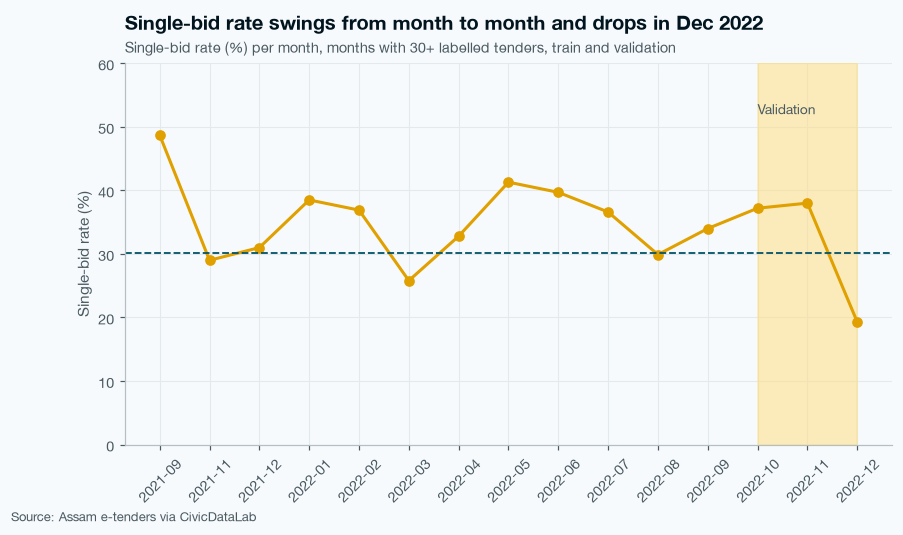

In [24]:
# Make the chart and draw the monthly line
fig, ax = plt.subplots(figsize=(9, 4.5))
x = by_month.index.astype(str)
ax.plot(x, by_month["rate"], color=ts.SINGLE, marker="o")

# Shade the validation months (Oct-Dec 2022) with a small label
ax.axvspan("2022-10", "2022-12", color=ts.HILITE, alpha=0.5)
ax.text("2022-10", 52, "Validation", color=ts.INK2, fontsize=9)

# Dashed benchmark line at the overall 30.1%
ax.axhline(30.1, color=ts.THIRD, linestyle="--", linewidth=1.2)

# Y-axis name, room at the top, tilted month labels
ax.set_ylabel("Single-bid rate (%)")
ax.set_ylim(0, 60)
ax.tick_params(axis="x", rotation=45)

# Title = the finding, subtitle = what is measured, then the source line
ts.title(ax, "Single-bid rate swings from month to month and drops in Dec 2022",
         subtitle="Single-bid rate (%) per month, months with 30+ labelled tenders, train and validation")
ts.source(fig)

In [25]:
# Make sure the folder exists, then save the chart
os.makedirs("../reports/figures", exist_ok=True)
ts.save_fig(fig, "../reports/figures/S5a_monthly_single_bid_rate.png")

### Insight · Labels and monthly drift (Steps 2 and 3)
- First I checked that the answer column means the same thing in every period. single_bid is 1 exactly when number_of_bids is 1, for all 6,790 tenders, so the labels are clean.
- The mix of bids changed a lot. In train 36.1% of tenders got 1 bid and 12.8% got 2 bids. In validation only 27.8% got 1 bid and 21.1% got 2 bids. So many tenders moved from "1 bid" to "2 bids" in the new period.
- Month by month, the single-bid rate keeps moving between about 26% and 41% in training. There is no fixed level.
- October and November 2022 look normal (37.2% and 38.0%). Then December 2022 drops to 19.3%, the lowest month in the whole chart, and it is also the biggest month with 1,221 tenders.
- This means more than half of validation sits in one unusual month. Any model trained on the older months will find December hard.

## Step 4 · Drift check 2: clues that flipped between train and validation

In [26]:
# Departments: number of tenders and single-bid rate (%) in train
dept = pd.DataFrame()
dept["train n"] = train["dept_main"].value_counts()
dept["train %"] = train.groupby("dept_main")["single_bid"].mean() * 100

In [27]:
# Same for validation
dept["val n"] = val["dept_main"].value_counts()
dept["val %"] = val.groupby("dept_main")["single_bid"].mean() * 100

In [28]:
# Change from train to validation (minus = fewer single bids later)
dept["change"] = dept["val %"] - dept["train %"]

In [29]:
# Keep departments with at least 40 tenders in BOTH periods, biggest first
dept = dept[(dept["train n"] >= 40) & (dept["val n"] >= 40)]
dept = dept.sort_values("train n", ascending=False)
dept.round(1)

,train n,train %,val n,val %,change
dept_main,,,,,
Public Works Building and NH Department,417,37.2,238.0,39.1,1.9
Public Works Roads Department,263,44.1,695.0,16.8,-27.3
National Health Mission,225,34.7,312.0,9.0,-25.7
Bodoland Territorial Council,150,24.7,360.0,44.7,20.1
Industries and Commerce Department,138,37.0,46.0,13.0,-23.9
Department of Water Resources,106,36.8,73.0,31.5,-5.3
Pr. Chief Conservator of Forest and Head of Forest Force,56,35.7,42.0,31.0,-4.8


In [30]:
# Category: single-bid rate (%) in train vs validation
cat_check = pd.DataFrame()
cat_check["train %"] = train.groupby("category")["single_bid"].mean() * 100
cat_check["val %"] = val.groupby("category")["single_bid"].mean() * 100
cat_check.round(1)

,train %,val %
category,,
Goods,28.2,27.5
Services,35.2,39.2
Works,37.6,26.6


In [31]:
# Contract form: single-bid rate (%) in train vs validation
form_check = pd.DataFrame()
form_check["train n"] = train["contract_form"].value_counts()
form_check["train %"] = train.groupby("contract_form")["single_bid"].mean() * 100
form_check["val %"] = val.groupby("contract_form")["single_bid"].mean() * 100
form_check.round(1).head(8)

,train n,train %,val %
contract_form,,,
Item Rate,1357,37.7,25.8
Works,505,35.0,41.3
Turn-key,257,34.6,10.1
Supply,236,29.2,29.9
Lump-sum,197,45.7,47.4
Item Wise,118,22.0,41.1
Percentage,33,27.3,50.0
EOI,24,50.0,0.0


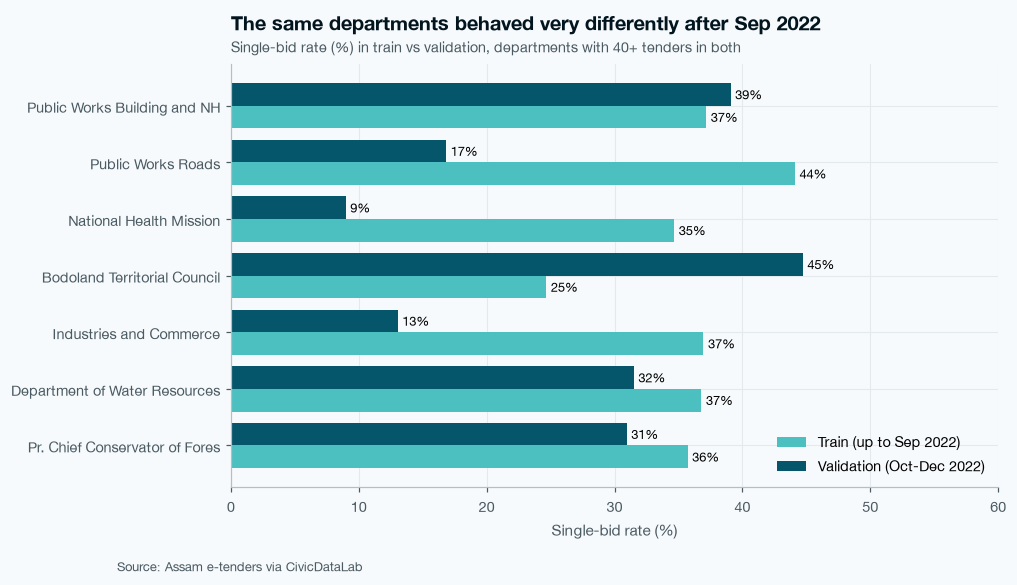

In [32]:
# Make the chart: train vs validation bars for each big department (sideways so names fit)
fig, ax = plt.subplots(figsize=(9, 5))
names = dept.index.str.replace(" Department", "").str[:30]
pos = np.arange(len(names))
b1 = ax.barh(pos + 0.2, dept["train %"], height=0.4, color=ts.BLUES[2], label="Train (up to Sep 2022)")
b2 = ax.barh(pos - 0.2, dept["val %"], height=0.4, color=ts.BLUES[4], label="Validation (Oct-Dec 2022)")

# % labels on the bars
ax.bar_label(b1, fmt="%.0f%%", padding=3, fontsize=8.5)
ax.bar_label(b2, fmt="%.0f%%", padding=3, fontsize=8.5)

# Department names, biggest on top, x-axis name and room, legend
ax.set_yticks(pos, names)
ax.invert_yaxis()
ax.set_xlabel("Single-bid rate (%)")
ax.set_xlim(0, 60)
ax.legend(loc="lower right")

# Title = the finding, then the source line
ts.title(ax, "The same departments behaved very differently after Sep 2022",
         subtitle="Single-bid rate (%) in train vs validation, departments with 40+ tenders in both")
ts.source(fig)

In [33]:
# Save the chart
ts.save_fig(fig, "../reports/figures/S5b_department_flip.png")

## Step 5 · Drift check 3: can a model tell old tenders from new ones?

The idea: we hide the dates and ask a model "is this tender from train or from validation?".
- Score near 0.5 = it cannot tell, the two periods look alike.
- Score near 1 = it can tell easily, the periods are really different, so patterns learned on old tenders may not work on new ones.

We use only clues that are made the same way in every period. months_to_fy_end is left out because it is just the calendar month (Oct-Dec would give the answer away). dept_rate is left out because train rows and validation rows get it in different ways (Step 7 and 8 of S4).

In [34]:
# Tools to cut the data into 5 parts and score each part
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score

In [35]:
# Clues made the same way in every period
same_way = ["log_value", "value_missing", "bid_window_days", "same_day_lot", "retender_60d"]

In [36]:
# Answer for this test only: 1 = validation tender, 0 = train tender
is_new = (tv["split"] == "val").astype(int)

In [37]:
# A forest model (each leaf needs 20+ tenders) and 5 shuffled parts
rf_check = RandomForestClassifier(n_estimators=200, min_samples_leaf=20, random_state=42)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [38]:
# Train on 4 parts, score on the 5th, 5 times; then take the average score
old_new = cross_val_score(rf_check, tv[same_way], is_new, cv=folds, scoring="roc_auc")
print("Old vs new ROC-AUC:", old_new.mean().round(3))

Old vs new ROC-AUC: 0.818


In [39]:
# Train once on everything, then see which clue gives the period away most
rf_check.fit(tv[same_way], is_new)
pd.Series(rf_check.feature_importances_, index=same_way).sort_values(ascending=False).round(3)

bid_window_days    0.477
log_value          0.364
value_missing      0.129
same_day_lot       0.026
retender_60d       0.004
dtype: float64

### Insight · Drift (Steps 4 and 5)
- The same departments behaved very differently after Sep 2022. PWD Roads went from 44.1% single-bid in train to 16.8% in validation. National Health Mission went from 34.7% to 9.0%. Industries and Commerce went from 37.0% to 13.0%.
- Some departments moved the other way. Bodoland Territorial Council went up from 24.7% to 44.7%. PWD Building stayed almost the same (37.2% to 39.1%).
- Category and contract form also changed. Works tenders fell from 37.6% to 26.6%. Turn-key contracts fell from 34.6% to 10.1%, and Item Rate from 37.7% to 25.8%.
- So the "department clue" the model learned in training points the wrong way for some big departments in validation. PWD Roads alone has 695 validation tenders.
- To test this properly, I asked a model to guess if a tender is from the old or the new period, without showing dates. It got an ROC-AUC of 0.818. If the periods looked the same it would get about 0.5. So the old and new tenders are clearly different.
- The clues that gave the period away most were bid_window_days (0.477) and log_value (0.364). This means the bid windows and tender values themselves changed between the periods.
- This change over time is called drift. It is the main reason the models struggle on validation.

## Step 6 · Extra clues (all known on the day the tender is published)

### 6a · Category

In [40]:
# Category as 0/1 columns: cat_Goods, cat_Services, cat_Works
cat = pd.get_dummies(lab["category"], prefix="cat", dtype=int)
cat.sum()

cat_Goods        759
cat_Services     482
cat_Works       5549
dtype: int64

### 6b · Contract form

In [41]:
# Contract forms with 30+ training tenders keep their name
train_forms = train["contract_form"].value_counts()
keep_forms = train_forms[train_forms >= 30].index

In [42]:
# Every other (rare) form becomes "Other"
lab["form_group"] = lab["contract_form"]
lab.loc[~lab["contract_form"].isin(keep_forms), "form_group"] = "Other"

In [43]:
# Contract form groups as 0/1 columns
form = pd.get_dummies(lab["form_group"], prefix="form", dtype=int)
form.sum()

form_Item Rate     3502
form_Item Wise      258
form_Lump-sum       400
form_Other          109
form_Percentage     118
form_Supply         455
form_Turn-key       679
form_Works         1269
dtype: int64

### 6c · Not an open tender

In [44]:
# 1 if the tender is NOT a normal open tender (Limited, Single, Global ...)
lab["not_open"] = (lab["tender_type"] != "Open Tender").astype(int)
lab["not_open"].sum()

176

### 6d · Title word flags

In [45]:
# Words to look for in the title
words = ["maintenance", "printing", "supply", "building", "construction", "road", "repair", "renovation"]

In [46]:
# Title in small letters so "ROAD" and "road" match
title_low = lab["title"].str.lower().fillna("")

In [47]:
# One 0/1 column per word, like kw_road (1 = the title has the word)
for w in words:
    lab["kw_" + w] = title_low.str.contains(w).astype(int)

### 6e · Product category past rate (built exactly like dept_rate in S4)

In [48]:
# Same settings as S4: overall training rate and 20 pretend average tenders
overall = 0.3607
k = 20

In [49]:
# Training rows in date order
tr = lab[lab["split"] == "train"]

In [50]:
# Tenders and single-bids per product category in training
pc_n = tr.groupby("product_category").size()
pc_ones = tr.groupby("product_category")["single_bid"].sum()

In [51]:
# Smoothed rate = (real single-bids + 20 average ones) / (real tenders + 20)
pc_rate = (pc_ones + k * overall) / (pc_n + k)

In [52]:
# Validation and test rows get the training rate (unknown categories get the overall rate)
not_train = lab["split"] != "train"
lab.loc[not_train, "prod_rate"] = lab.loc[not_train, "product_category"].map(pc_rate).fillna(overall)

In [53]:
# Training rows: count only EARLIER training tenders of the same product category
prior_n = tr.groupby("product_category").cumcount()
prior_ones = tr.groupby("product_category")["single_bid"].cumsum() - tr["single_bid"]

In [54]:
# Smoothed rate from earlier tenders only, written into the training rows
lab.loc[tr.index, "prod_rate"] = (prior_ones + k * overall) / (prior_n + k)

In [55]:
# Check: no empty prod_rate
lab["prod_rate"].isna().sum()

0

### 6f · Weak clues (tested once and reported)

In [56]:
# EMD (security money) as a share of the tender value
lab["emd_ratio"] = lab["emd_amount"] / lab["estimated_value"]

In [57]:
# Tender fee squeezed with log (like log_value)
lab["log_fee"] = np.log1p(lab["tender_fee"])

In [58]:
# Day of the week (0 = Monday ... 6 = Sunday) and the hour it was published
lab["weekday"] = lab["published_date"].dt.dayofweek
lab["pub_hour"] = lab["published_date"].dt.hour

In [59]:
# Fill empty values with TRAINING medians only (same rule as S4)
fill_cols = ["emd_ratio", "log_fee", "work_period_days"]
fill_values = lab.loc[lab["split"] == "train", fill_cols].median()
fill_values

emd_ratio             0.020000
log_fee               7.465083
work_period_days    180.000000
dtype: float64

In [60]:
# Put the medians into the empty cells
lab[fill_cols] = lab[fill_cols].fillna(fill_values)

### 6g · Final clue lists

In [61]:
# Add the 0/1 category and contract form columns to lab
lab = pd.concat([lab, cat, form], axis=1)

In [62]:
# The 7 clues from S4
base = ["dept_rate", "log_value", "value_missing", "bid_window_days",
        "months_to_fy_end", "same_day_lot", "retender_60d"]

In [63]:
# The new clues from this step
new = list(cat.columns) + list(form.columns)
new = new + ["not_open", "prod_rate", "times_before"]
new = new + ["kw_" + w for w in words]
new = new + ["emd_ratio", "log_fee", "work_period_days", "weekday", "pub_hour"]

In [64]:
# Full clue list = base + new
full = base + new
print(len(base), "base clues +", len(new), "new clues =", len(full))

7 base clues + 27 new clues = 34


In [65]:
# Make train and val again, so they include the new clue columns
train = lab[lab["split"] == "train"]
val = lab[lab["split"] == "val"]

In [66]:
# Do the new word clues hold up over time? Single-bid rate (%) when the flag is 1
for col in ["not_open", "kw_maintenance", "kw_building", "kw_repair", "kw_renovation"]:
    print(col, "| train:", round(train.loc[train[col] == 1, "single_bid"].mean() * 100, 1),
          "| val:", round(val.loc[val[col] == 1, "single_bid"].mean() * 100, 1))

not_open | train: 45.0 | val: 25.0
kw_maintenance | train: 41.2 | val: 9.2
kw_building | train: 47.4 | val: 15.0
kw_repair | train: 37.7 | val: 34.2
kw_renovation | train: 34.1 | val: 48.0


### Insight · Extra clues (Step 6)
- I added 27 new clues that are known on the day a tender is published: category (3 columns), contract form (8 columns, rare forms grouped as Other), not_open, product category past rate, times_before, 8 title word flags and 5 weak clues (emd_ratio, log_fee, work_period_days, weekday, pub_hour). Total clues = 7 base + 27 new = 34.
- prod_rate was built exactly like dept_rate in S4: validation and test use training rates, and training rows use only earlier training tenders, so there is no peeking.
- Empty values were filled with training medians only. EMD is usually exactly 2% of the value, the median tender fee gives log_fee 7.47 (about Rs 1,750), and the median work period is 180 days.
- Many new clues flipped over time, just like departments. Titles with "maintenance" were 41.2% single-bid in train but 9.2% in validation. "Building" went from 47.4% to 15.0%. Non-open tenders went from 45.0% to 25.0%.
- Only a few held steady, like "repair" (37.7% to 34.2%). "Renovation" went the other way, from 34.1% to 48.0%.
- So the earlier whole-data rates in my checklist were misleading, because they mixed all years together. A clue must be checked on train vs validation, not on the full data.

## Step 7 · Score helpers (one way to score every model)

How we score (validation base rate is about 27.8%):
- PR-AUC: how well single-bid tenders are pushed to the top. Random guessing gets about the base rate (0.28).
- ROC-AUC: 0.5 = coin toss, 1 = perfect ranking.
- Capture top 20%: if an auditor checks only the riskiest 20% of tenders, what share of ALL single-bid tenders do they catch? Random checking catches about 20%.

In [67]:
# The real answers for train and validation
y_tr = train["single_bid"]
y_va = val["single_bid"]

In [68]:
# Helper 1: share (%) of all single-bid tenders found in the riskiest top part
def capture(y, risk, share):
    t = pd.DataFrame({"real": y.values, "risk": risk})              # answers next to risk scores
    t = t.sort_values("risk", ascending=False, kind="stable")       # riskiest first (ties keep date order)
    top = t.head(int(len(t) * share))                               # keep the top part, e.g. 20%
    return top["real"].sum() / t["real"].sum() * 100                # caught / all single-bids

In [69]:
# Helper 2: all scores for one model as one row of the results table
def score_row(name, y, risk):
    row = {"model": name}                                           # model name first
    row["PR-AUC"] = round(average_precision_score(y, risk), 3)      # ranking score for single-bids
    row["ROC-AUC"] = round(roc_auc_score(y, risk), 3)               # 0.5 = coin toss
    row["capture top 10%"] = round(capture(y, risk, 0.1), 1)        # caught when checking 10%
    row["capture top 20%"] = round(capture(y, risk, 0.2), 1)        # caught when checking 20%
    return row

In [70]:
# Empty results list: every model adds one row
results = []

## Step 8 · Benchmarks (every model must beat these)

In [71]:
# Random: every tender gets a random risk (seed 42 so it is the same every run)
rng = np.random.default_rng(42)
p_random = rng.random(len(val))
results.append(score_row("Random", y_va, p_random))

In [72]:
# Rule A: departments with a high past single-bid rate first
p_rule_dept = val["dept_rate"].values
results.append(score_row("Rule: dept rate", y_va, p_rule_dept))

In [73]:
# Rule B: quick re-tenders first, then by department rate (dept_rate / 10 only breaks ties)
p_rule_retender = (val["retender_60d"] + val["dept_rate"] / 10).values
results.append(score_row("Rule: re-tender then dept", y_va, p_rule_retender))

In [74]:
# See the benchmark scores
pd.DataFrame(results)

,model,PR-AUC,ROC-AUC,capture top 10%,capture top 20%
0,Random,0.288,0.514,11.1,19.8
1,Rule: dept rate,0.247,0.412,9.7,11.1
2,Rule: re-tender then dept,0.268,0.431,12.5,14.6


## Step 9 · Logistic Regression

### 9a · Base 7 clues, written out step by step

In [75]:
# 1. Learn the average and spread of each clue from TRAINING only
scaler = StandardScaler()
scaler.fit(train[base])

StandardScaler()

In [76]:
# 2. Put train and validation clues on the same scale
X_tr = scaler.transform(train[base])
X_va = scaler.transform(val[base])

In [77]:
# 3. The model; balanced = single-bid tenders count more because there are fewer of them
lr = LogisticRegression(class_weight="balanced", max_iter=2000)

In [78]:
# 4. Learn from training tenders and their answers
lr.fit(X_tr, y_tr)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Defaul

In [79]:
# 5. Risk score (0 to 1) for every validation tender
p_lr_base = lr.predict_proba(X_va)[:, 1]

In [80]:
# 6. Score it and add the row
results.append(score_row("LogReg (base 7)", y_va, p_lr_base))
pd.DataFrame(results).tail(1)

,model,PR-AUC,ROC-AUC,capture top 10%,capture top 20%
3,LogReg (base 7),0.252,0.426,9.0,11.7


### 9b · The same 6 steps as one small helper (so we do not repeat them)

In [81]:
# Helper 3: scale, train Logistic Regression, return risk scores
def lr_risk(learn, answers, score, clues, weight=None):
    scaler = StandardScaler().fit(learn[clues])                      # 1. learn scale from learning rows
    model = LogisticRegression(class_weight="balanced", max_iter=2000)   # 3. the model
    model.fit(scaler.transform(learn[clues]), answers, sample_weight=weight)  # 2 + 4. scale and learn
    return model.predict_proba(scaler.transform(score[clues]))[:, 1]     # 5. risk scores

In [82]:
# All clues (base + new)
p_lr_all = lr_risk(train, y_tr, val, full)
results.append(score_row("LogReg (all clues)", y_va, p_lr_all))
pd.DataFrame(results).tail(1)

,model,PR-AUC,ROC-AUC,capture top 10%,capture top 20%
4,LogReg (all clues),0.245,0.417,7.3,15.2


## Step 10 · Random Forest

In [83]:
# 300 trees; each leaf needs 20+ tenders so trees do not memorise single tenders
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight="balanced", random_state=42)

In [84]:
# Base 7 clues: learn, then risk scores for validation
rf.fit(train[base], y_tr)
p_rf_base = rf.predict_proba(val[base])[:, 1]
results.append(score_row("Random Forest (base 7)", y_va, p_rf_base))

In [85]:
# All clues: learn again, then risk scores
rf.fit(train[full], y_tr)
p_rf_all = rf.predict_proba(val[full])[:, 1]
results.append(score_row("Random Forest (all clues)", y_va, p_rf_all))

In [86]:
pd.DataFrame(results).tail(2)

,model,PR-AUC,ROC-AUC,capture top 10%,capture top 20%
5,Random Forest (base 7),0.233,0.415,6.0,15.7
6,Random Forest (all clues),0.236,0.406,8.3,15.2


## Step 11 · XGBoost

In [87]:
# Weight for single-bid tenders = multi-bid count / single-bid count (XGBoost's "balanced")
pos_weight = (y_tr == 0).sum() / (y_tr == 1).sum()
round(pos_weight, 2)

1.77

In [88]:
# Small trees (3 questions each), slow learning (0.05), each tree sees 80% of rows and clues
xgb = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
                    colsample_bytree=0.8, scale_pos_weight=pos_weight, random_state=42)

In [89]:
# Base 7 clues
xgb.fit(train[base], y_tr)
p_xgb_base = xgb.predict_proba(val[base])[:, 1]
results.append(score_row("XGBoost (base 7)", y_va, p_xgb_base))

In [90]:
# All clues
xgb.fit(train[full], y_tr)
p_xgb_all = xgb.predict_proba(val[full])[:, 1]
results.append(score_row("XGBoost (all clues)", y_va, p_xgb_all))

In [91]:
pd.DataFrame(results).tail(2)

,model,PR-AUC,ROC-AUC,capture top 10%,capture top 20%
7,XGBoost (base 7),0.223,0.393,4.4,11.6
8,XGBoost (all clues),0.222,0.385,5.2,11.7


## Step 12 · Comparison table + Oct-Nov vs December

In [92]:
# All results in one table, best PR-AUC first
table = pd.DataFrame(results).sort_values("PR-AUC", ascending=False)
table

,model,PR-AUC,ROC-AUC,capture top 10%,capture top 20%
0,Random,0.288,0.514,11.1,19.8
2,Rule: re-tender then dept,0.268,0.431,12.5,14.6
3,LogReg (base 7),0.252,0.426,9.0,11.7
1,Rule: dept rate,0.247,0.412,9.7,11.1
4,LogReg (all clues),0.245,0.417,7.3,15.2
6,Random Forest (all clues),0.236,0.406,8.3,15.2
5,Random Forest (base 7),0.233,0.415,6.0,15.7
7,XGBoost (base 7),0.223,0.393,4.4,11.6
8,XGBoost (all clues),0.222,0.385,5.2,11.7


In [93]:
# True for December validation tenders, False for the rest
dec = (val["published_date"].dt.month == 12).values

In [94]:
# Single-bid rate (%) before December and in December
print("Oct-Nov:", round(y_va[~dec].mean() * 100, 1), "%   Dec:", round(y_va[dec].mean() * 100, 1), "%")

Oct-Nov: 37.6 %   Dec: 19.3 %


In [95]:
# ROC-AUC before December and in December for 4 methods
for name, risk in [("Random", p_random), ("Rule B", p_rule_retender),
                   ("LogReg base", p_lr_base), ("XGBoost all", p_xgb_all)]:
    print(name, "| Oct-Nov:", round(roc_auc_score(y_va[~dec], risk[~dec]), 3),
          "| Dec:", round(roc_auc_score(y_va[dec], risk[dec]), 3))

Random | Oct-Nov: 0.526 | Dec: 0.501
Rule B | Oct-Nov: 0.482 | Dec: 0.465
LogReg base | Oct-Nov: 0.487 | Dec: 0.418
XGBoost all | Oct-Nov: 0.461 | Dec: 0.397


### Insight · Model comparison (Steps 8 to 12)
- I compared every model with random checking and two simple rules. On validation 27.8% of tenders are single-bid, so random checking catches about 20% of them in the top 20%.
- Random got PR-AUC 0.288 and caught 19.8% in the top 20%. Rule B (re-tenders first, then department rate) got PR-AUC 0.268 and caught 14.6%.
- Logistic Regression with the base 7 clues got PR-AUC 0.252. Random Forest got 0.233 to 0.236. XGBoost got 0.222 to 0.223. All of them have ROC-AUC between 0.385 and 0.426, which is below the 0.5 coin-toss level.
- Adding the 27 new clues did not help. Logistic Regression went from 0.252 to 0.245, and XGBoost stayed about the same.
- The more complex models (Random Forest, XGBoost) did worse than the simple Logistic Regression. They learned the old patterns more strongly, so they were more wrong when the patterns flipped.
- Before December the models are close to coin toss (Logistic Regression ROC 0.487 in Oct-Nov). In December they drop further (0.418), because December is the month that changed most (37.6% single-bid in Oct-Nov vs 19.3% in Dec).
- My honest result: on validation, no model beats random checking. This is not a coding mistake. It is because the pattern changed after Sep 2022.)

## Step 13 · Do the clues work INSIDE the training period?

The idea: inside training, learn from earlier months and score the next 3 months. If the clues work here but not on validation, the problem is drift (the world changed), not a broken model.

In [96]:
# Check 1: learn from tenders before Apr 2022, score Apr-Jun 2022
learn = train[train["published_date"] < "2022-04-01"]
check = train[(train["published_date"] >= "2022-04-01") & (train["published_date"] < "2022-07-01")]

In [97]:
risk = lr_risk(learn, learn["single_bid"], check, base)
print("Learned from", len(learn), "| scored", len(check), "| ROC", round(roc_auc_score(check["single_bid"], risk), 3))

Learned from 727 | scored 1042 | ROC 0.531


In [98]:
# Check 2: learn from tenders before Jul 2022, score Jul-Sep 2022
learn = train[train["published_date"] < "2022-07-01"]
check = train[train["published_date"] >= "2022-07-01"]

In [99]:
risk = lr_risk(learn, learn["single_bid"], check, base)
print("Learned from", len(learn), "| scored", len(check), "| ROC", round(roc_auc_score(check["single_bid"], risk), 3))

Learned from 1769 | scored 984 | ROC 0.577


## Step 14 · Three fixes for drift (tried on validation only)

1. Recent only: learn only from 2022 tenders (forget old habits).
2. Recent counts more: a tender's weight halves for every 6 months of age.
3. Monthly retraining: before each new month, learn again from every tender whose answer we already know. This is how an auditor would really use TenderLens.

### Fix 1 · Recent only

In [100]:
# Training tenders from 2022 only
recent = train[train["published_date"] >= "2022-01-01"]
len(recent)

2419

In [101]:
# Logistic Regression on recent tenders
p_lr_recent = lr_risk(recent, recent["single_bid"], val, base)
results.append(score_row("LogReg recent only", y_va, p_lr_recent))

In [102]:
# XGBoost on recent tenders
xgb.fit(recent[base], recent["single_bid"])
p_xgb_recent = xgb.predict_proba(val[base])[:, 1]
results.append(score_row("XGBoost recent only", y_va, p_xgb_recent))
pd.DataFrame(results).tail(2)

,model,PR-AUC,ROC-AUC,capture top 10%,capture top 20%
9,LogReg recent only,0.250,0.424,9.2,12.4
10,XGBoost recent only,0.223,0.398,3.2,9.2


### Fix 2 · Recent counts more

In [103]:
# Age of each training tender in months, counted back from 1 Oct 2022
age = (pd.Timestamp("2022-10-01") - train["published_date"]).dt.days / 30

In [104]:
# Weight halves every 6 months: new = 1, 6 months old = 0.5, 12 months old = 0.25
weight = 0.5 ** (age / 6)

In [105]:
p_lr_weighted = lr_risk(train, y_tr, val, base, weight=weight)
results.append(score_row("LogReg recent counts more", y_va, p_lr_weighted))
pd.DataFrame(results).tail(1)

,model,PR-AUC,ROC-AUC,capture top 10%,capture top 20%
11,LogReg recent counts more,0.251,0.423,9.4,12.2


### Fix 3 · Monthly retraining

In [106]:
# An empty risk column for validation, filled month by month
p_lr_monthly = pd.Series(0.0, index=val.index)

In [107]:
# Month 1 (October, plus the few moved-forward tenders dated before Oct): learn from train only
rows = val["published_date"] < "2022-11-01"
p_lr_monthly[rows] = lr_risk(train, y_tr, val[rows], base)
print("Learned from", len(train), "| scored", rows.sum())

Learned from 2753 | scored 317


In [108]:
# Month 2 (November): learn from train + validation tenders before November
learn = pd.concat([train, val[val["published_date"] < "2022-11-01"]])
rows = (val["published_date"] >= "2022-11-01") & (val["published_date"] < "2022-12-01")
p_lr_monthly[rows] = lr_risk(learn, learn["single_bid"], val[rows], base)
print("Learned from", len(learn), "| scored", rows.sum())

Learned from 3070 | scored 732


In [109]:
# Month 3 (December): learn from train + validation tenders before December
learn = pd.concat([train, val[val["published_date"] < "2022-12-01"]])
rows = val["published_date"] >= "2022-12-01"
p_lr_monthly[rows] = lr_risk(learn, learn["single_bid"], val[rows], base)
print("Learned from", len(learn), "| scored", rows.sum())

Learned from 3802 | scored 1221


In [110]:
# Score all three months together
p_lr_monthly = p_lr_monthly.values
results.append(score_row("LogReg monthly retrain", y_va, p_lr_monthly))
pd.DataFrame(results).tail(1)

,model,PR-AUC,ROC-AUC,capture top 10%,capture top 20%
12,LogReg monthly retrain,0.258,0.43,12.2,17.8


## Step 15 · Full results table

In [111]:
table = pd.DataFrame(results).sort_values("PR-AUC", ascending=False)
table

,model,PR-AUC,ROC-AUC,capture top 10%,capture top 20%
0,Random,0.288,0.514,11.1,19.8
2,Rule: re-tender then dept,0.268,0.431,12.5,14.6
12,LogReg monthly retrain,0.258,0.430,12.2,17.8
3,LogReg (base 7),0.252,0.426,9.0,11.7
11,LogReg recent counts more,0.251,0.423,9.4,12.2
9,LogReg recent only,0.250,0.424,9.2,12.4
1,Rule: dept rate,0.247,0.412,9.7,11.1
4,LogReg (all clues),0.245,0.417,7.3,15.2
6,Random Forest (all clues),0.236,0.406,8.3,15.2
5,Random Forest (base 7),0.233,0.415,6.0,15.7


### Insight · Inside training and drift fixes (Steps 13 to 15)
- To check if the clues are useless or if the world changed, I tested inside the training period only.
- Learning from tenders before Apr 2022 and scoring Apr-Jun 2022 gave ROC-AUC 0.531. Learning before Jul 2022 and scoring Jul-Sep 2022 gave 0.577.
- So inside training the clues do work, a little. The signal is weak but real. It breaks after Sep 2022, which again points to drift, not a broken model.
- I tried three fixes, all checked on validation only. Learning from 2022 tenders only gave PR-AUC 0.250. Giving recent tenders more weight (weight halves every 6 months) gave 0.251. Neither helped compared with plain Logistic Regression (0.252).
- Monthly retraining was the best real model: PR-AUC 0.258, and it caught 17.8% of single-bid tenders in the top 20%, compared with 11.7% for plain Logistic Regression.
- Monthly retraining means: before each new month, learn again from every tender whose answer is already known. This is how an auditor would really use the tool. It helps a little, but it still does not beat random checking (19.8%).

## Step 16 · Fair checks: repeated lots and lucky scores

The best real model in the table above (not random, not a rule) is LogReg monthly retrain, so we call its risk scores p_best.

In [112]:
# Risk scores of the best real model
p_best = p_lr_monthly

In [113]:
# Repeated lots: True for the first tender of each department + title in validation, False for copies
first_only = ~val.duplicated(["dept_main", "title_key"]).values
print("Validation tenders:", len(val), "| counting repeats once:", first_only.sum())

Validation tenders: 2270 | counting repeats once: 2157


In [114]:
# PR-AUC with all tenders vs with repeats counted once
print("Best model | all:", round(average_precision_score(y_va, p_best), 3),
      "| repeats once:", round(average_precision_score(y_va[first_only], p_best[first_only]), 3))
print("Rule B     | all:", round(average_precision_score(y_va, p_rule_retender), 3),
      "| repeats once:", round(average_precision_score(y_va[first_only], p_rule_retender[first_only]), 3))

Best model | all: 0.258 | repeats once: 0.254
Rule B     | all: 0.268 | repeats once: 0.261


In [115]:
# Answers as a plain array, and a fixed random seed
y_arr = y_va.values
rng = np.random.default_rng(42)

In [116]:
# 500 re-draws: PR-AUC of the best model minus PR-AUC of Rule B
gaps = []
for i in range(500):
    pick = rng.integers(0, len(val), len(val))
    gap = average_precision_score(y_arr[pick], p_best[pick]) - average_precision_score(y_arr[pick], p_rule_retender[pick])
    gaps.append(gap)

In [117]:
# How often the best model wins, and the middle 95% of the gap
gaps = np.array(gaps)
print("Best model beats Rule B in", round((gaps > 0).mean() * 100, 1), "% of draws")
print("Middle 95% of the gap:", np.percentile(gaps, [2.5, 97.5]).round(3))

Best model beats Rule B in 14.8 % of draws
Middle 95% of the gap: [-0.033  0.01 ]


In [118]:
# Same check against Random
rng = np.random.default_rng(42)
gaps = []
for i in range(500):
    pick = rng.integers(0, len(val), len(val))
    gap = average_precision_score(y_arr[pick], p_best[pick]) - average_precision_score(y_arr[pick], p_random[pick])
    gaps.append(gap)

In [119]:
gaps = np.array(gaps)
print("Best model beats Random in", round((gaps > 0).mean() * 100, 1), "% of draws")
print("Middle 95% of the gap:", np.percentile(gaps, [2.5, 97.5]).round(3))

Best model beats Random in 0.8 % of draws
Middle 95% of the gap: [-0.059 -0.005]


## Step 17 · Threshold and calibration

In [120]:
# Threshold = the risk score at the top-20% line (the auditor checks the riskiest 20%)
cut = np.quantile(p_best, 0.8)
round(cut, 3)

0.529

In [121]:
# 1 = flagged for checking, 0 = not flagged
flag = (p_best >= cut).astype(int)
flag.sum()

454

In [122]:
# Confusion table: rows = real answer, columns = flagged or not
pd.crosstab(y_va.values, flag, rownames=["real single bid"], colnames=["flagged"])

flagged,0,1
real single bid,,
0.0,1298,342
1.0,518,112


In [123]:
# Calibration: cut risk scores into 5 equal groups (lowest to highest)
groups = pd.qcut(p_best, 5, labels=["lowest", "low", "middle", "high", "highest"])

In [124]:
# In each group: average risk score (%) vs real single-bid rate (%)
calib = pd.DataFrame({"avg risk %": p_best * 100, "real single-bid %": y_va.values * 100})
calib.groupby(groups, observed=True).mean().round(1)

,avg risk %,real single-bid %
lowest,38.7,34.4
low,47.5,34.4
middle,50.1,28.2
high,52.4,17.2
highest,54.7,24.7


## Step 18 · Auditor view (check the riskiest 20%)

In [125]:
# How many tenders the auditor checks (20% of validation)
n_check = int(len(val) * 0.2)
n_check

454

In [126]:
# Helper 4: the riskiest 20% of validation tenders for any risk score
def top20(risk):
    t = val[["single_bid", "estimated_value"]].copy()               # answer and rupee value
    t["risk"] = risk                                                # add the risk score
    t = t.sort_values("risk", ascending=False, kind="stable")       # riskiest first
    return t.head(n_check)                                          # keep the top 20%

In [127]:
# Random checking: single-bid tenders caught and their value in crore (1 crore = 1,00,00,000)
top = top20(p_random)
print("Random | caught:", int(top["single_bid"].sum()), "| Rs crore:", round(top.loc[top["single_bid"] == 1, "estimated_value"].sum() / 1e7, 1))

Random | caught: 125 | Rs crore: 233.1


In [128]:
# Rule B
top = top20(p_rule_retender)
print("Rule B | caught:", int(top["single_bid"].sum()), "| Rs crore:", round(top.loc[top["single_bid"] == 1, "estimated_value"].sum() / 1e7, 1))

Rule B | caught: 92 | Rs crore: 425.9


In [129]:
# Best model
top = top20(p_best)
print("Best   | caught:", int(top["single_bid"].sum()), "| Rs crore:", round(top.loc[top["single_bid"] == 1, "estimated_value"].sum() / 1e7, 1))

Best   | caught: 112 | Rs crore: 422.5


In [130]:
# Total single-bid tenders in validation (to compare the caught numbers)
int(y_va.sum())

630

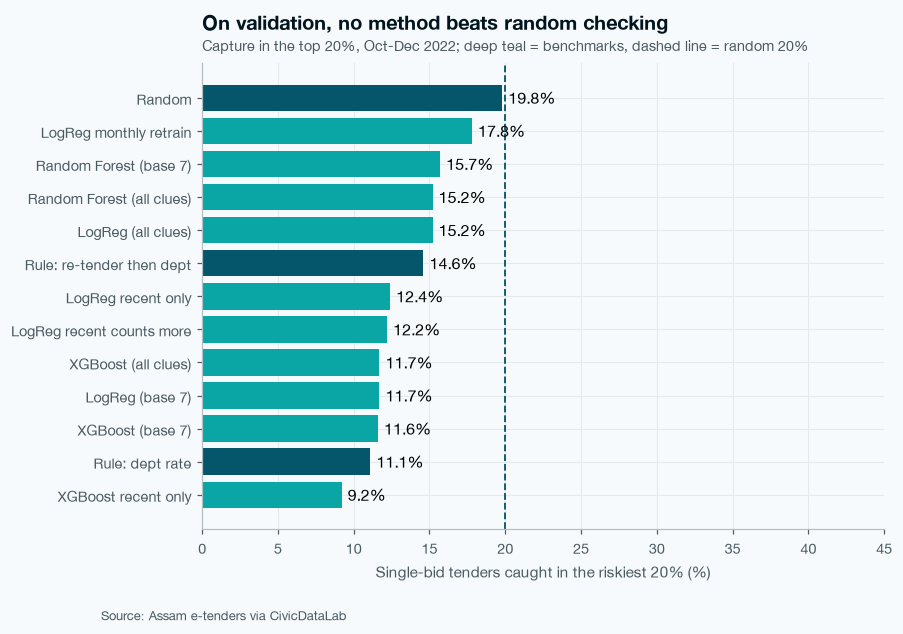

In [131]:
# Make the chart: share of single-bid tenders caught in the top 20% for every method
show = table.sort_values("capture top 20%")
benchmarks = ["Random", "Rule: dept rate", "Rule: re-tender then dept"]
colors = np.where(show["model"].isin(benchmarks), ts.THIRD, ts.MULTI)
fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.barh(show["model"], show["capture top 20%"], color=colors)

# Dashed line at 20% = what random checking catches, % labels on bars
ax.axvline(20, color=ts.THIRD, linestyle="--", linewidth=1.2)
ax.bar_label(bars, fmt="%.1f%%", padding=4)

# X-axis name and room
ax.set_xlabel("Single-bid tenders caught in the riskiest 20% (%)")
ax.set_xlim(0, 45)

# Title = the finding, then the source line
ts.title(ax, "On validation, no method beats random checking",
         subtitle="Capture in the top 20%, Oct-Dec 2022; deep teal = benchmarks, dashed line = random 20%")
ts.source(fig)

In [132]:
ts.save_fig(fig, "../reports/figures/S5c_capture_top20.png")

### Insight · Fair checks and auditor view (Steps 16 to 18)
- December has many copies of the same work (for example 81 "6 bedded ward" tenders). I counted each department + title only once (2,157 instead of 2,270 tenders). The scores barely changed (best model 0.258 to 0.254, Rule B 0.268 to 0.261), so the copies are not the reason for the weak results.
- To check if differences are real or just luck, I re-drew validation 500 times. The best model beat Rule B in only 14.8% of draws, and the gap range (-0.033 to 0.010) crosses zero. So the best model and Rule B are really the same level.
- Against random checking, the best model won in only 0.8% of draws, and the whole gap range is below zero (-0.059 to -0.005). So on validation it is truly a bit worse than random, not just unlucky.
- If an auditor checks the riskiest 20% (454 tenders), the best model catches 112 of the 630 single-bid tenders. Random checking catches 125.
- One interesting point: the single-bid tenders caught by the best model are worth Rs 422.5 crore, and by Rule B Rs 425.9 crore, compared with Rs 233.1 crore for random checking. So the model and the rule find fewer single-bid tenders but bigger ones. This is from one random draw only, so I will check it again on test in S7 before claiming it.
- Calibration shows the risk scores are not real percentages. The scores go from 38.7% to 54.7%, but the real single-bid rate goes the other way (34.4% in the lowest group, 17.2% to 24.7% in the top groups). Class weights push all scores up, and drift flips the order. So in the app I should show risk as a rank (high / medium / low), not as a percentage.

## Step 19 · Mistakes: where does the model go wrong?

In [133]:
# A small table of validation tenders with the best model's risk score
val_out = val[["tender_id", "published_date", "dept_main", "category", "title", "estimated_value", "single_bid"]].copy()
val_out["risk"] = p_best
val_out["flagged"] = flag

In [134]:
# By department: number of tenders, real single-bid rate (%), average risk (%)
by_dept = pd.DataFrame()
by_dept["tenders"] = val_out["dept_main"].value_counts()
by_dept["real %"] = val_out.groupby("dept_main")["single_bid"].mean() * 100
by_dept["avg risk %"] = val_out.groupby("dept_main")["risk"].mean() * 100

In [135]:
# Departments with 10+ tenders, biggest first
by_dept[by_dept["tenders"] >= 10].round(1).head(10)

,tenders,real %,avg risk %
dept_main,,,
Public Works Roads Department,695,16.8,53.5
Bodoland Territorial Council,360,44.7,41.9
National Health Mission,312,9.0,49.5
Public Works Building and NH Department,238,39.1,50.2
Food Civil Supplies and Consumer Affairs Department,120,53.3,48.5
Department of Water Resources,73,31.5,48.7
Industries and Commerce Department,46,13.0,41.5
Pr. Chief Conservator of Forest and Head of Forest Force,42,31.0,52.6
Irrigation Department,37,40.5,52.6


In [136]:
# By category
by_cat = pd.DataFrame()
by_cat["tenders"] = val_out["category"].value_counts()
by_cat["real %"] = val_out.groupby("category")["single_bid"].mean() * 100
by_cat["avg risk %"] = val_out.groupby("category")["risk"].mean() * 100
by_cat.round(1)

,tenders,real %,avg risk %
category,,,
Works,1940,26.6,49.5
Services,199,39.2,46.0
Goods,131,27.5,40.5


In [137]:
# 5 big misses: single-bid tenders that got the LOWEST risk scores
misses = val_out[val_out["single_bid"] == 1].sort_values("risk").head(5)
misses[["published_date", "dept_main", "title", "estimated_value", "risk"]]

,published_date,dept_main,title,estimated_value,risk
3699,2022-11-19 15:30:00,Health and Family Welfare Department,"Supply, Installation and Commissioning of Benc...",NaN,0.261074
2955,2022-10-17 14:55:00,Health and Family Welfare Department,EMPANELMENT OF PHARMACIES/SUPPLIER FOR SUPPLY ...,NaN,0.263087
3216,2022-10-31 09:00:00,Bodoland Territorial Council,Procurement of Hospital Equipments etc,NaN,0.268853
3890,2022-11-25 13:30:00,Cooperation Department,SS Milk Can (Capacity 5 litre and 10 litre),NaN,0.304302
4846,2022-12-15 17:00:00,Information - Public Relations - Printing and ...,Printing and Supply of New Year greetings card,NaN,0.309503


### Insight · Mistakes (Step 19)
- The model gave PWD Roads a high average risk (53.5%) but its real single-bid rate in validation was only 16.8%. Same for National Health Mission: risk 49.5% but real rate 9.0%. These two departments have 1,007 validation tenders together, so they pull the whole score down.
- The opposite happened for Bodoland Territorial Council: the model gave a lower risk (41.9%) but the real rate was 44.7%. Food Civil Supplies had a real rate of 53.3% but only 48.5% risk.
- By category, Works got the highest average risk (49.5%) but had the lowest real rate (26.6%). Services had the highest real rate (39.2%).
- The 5 biggest misses (single-bid tenders with the lowest risk) are all supply or equipment tenders, like hospital equipment, pharmacy empanelment, milk cans and greetings card printing. All 5 have no value written.
- The model learned in training that a missing value means a lower chance of single bid (the strongest minus weight, -0.18). In validation that rule failed for these goods and supply tenders.
- So the main mistakes come from big departments and clue rules that changed after Sep 2022, not from random noise.

## Step 20 · Which clues did the model lean on? (Logistic Regression, all clues)

In [138]:
# Scale all clues with training numbers, then train Logistic Regression
scaler = StandardScaler().fit(train[full])
lr_all = LogisticRegression(class_weight="balanced", max_iter=2000)
lr_all.fit(scaler.transform(train[full]), y_tr)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Defaul

In [139]:
# One weight per clue (plus = pushes towards single bid, minus = away)
weights = pd.Series(lr_all.coef_[0], index=full)
weights.sort_values().round(3)

value_missing      -0.182
form_Item Wise     -0.112
work_period_days   -0.100
kw_printing        -0.086
kw_renovation      -0.060
form_Turn-key      -0.057
form_Works         -0.047
retender_60d       -0.036
form_Percentage    -0.034
cat_Goods          -0.032
kw_supply          -0.021
cat_Works          -0.010
kw_road             0.001
log_value           0.007
same_day_lot        0.016
form_Item Rate      0.019
kw_maintenance      0.028
emd_ratio           0.029
times_before        0.048
kw_repair           0.050
pub_hour            0.056
form_Other          0.059
cat_Services        0.060
form_Supply         0.060
kw_construction     0.072
log_fee             0.076
prod_rate           0.085
bid_window_days     0.088
not_open            0.091
form_Lump-sum       0.103
months_to_fy_end    0.113
kw_building         0.142
weekday             0.156
dept_rate           0.200
dtype: float64

In [140]:
# The 12 clues with the biggest weights (ignoring plus or minus)
top_names = weights.abs().sort_values().tail(12).index
top = weights[top_names]

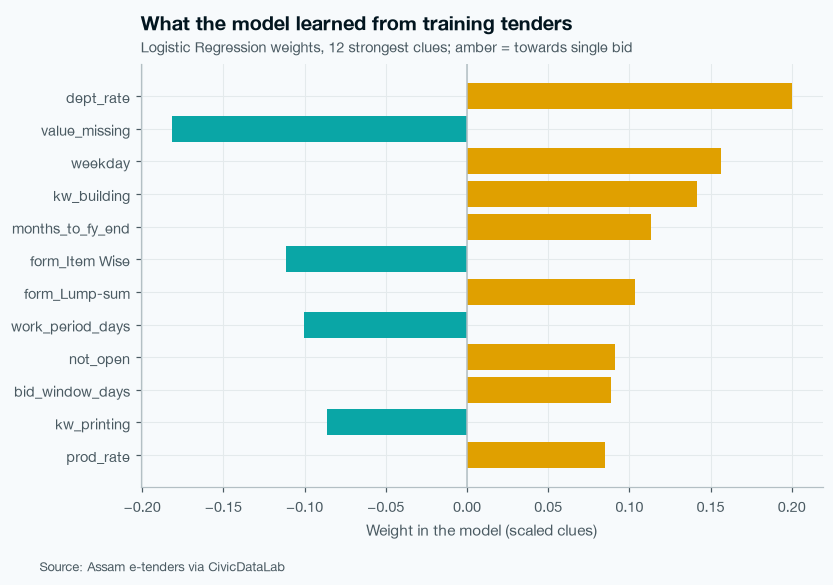

In [141]:
# Make the chart: amber = towards single bid, teal = away
colors = np.where(top > 0, ts.SINGLE, ts.MULTI)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color=colors)

# Zero line and x-axis name
ax.axvline(0, color=ts.AXIS, linewidth=1)
ax.set_xlabel("Weight in the model (scaled clues)")

# Title, then the source line
ts.title(ax, "What the model learned from training tenders",
         subtitle="Logistic Regression weights, 12 strongest clues; amber = towards single bid")
ts.source(fig)

In [142]:
ts.save_fig(fig, "../reports/figures/S5d_clue_weights.png")

## Step 21 · Second target: low competition (1 or 2 bids)

In [143]:
# 1 = one or two bids, 0 = three or more
low_tr = (train["number_of_bids"] <= 2).astype(int)
low_va = (val["number_of_bids"] <= 2).astype(int)
print("Low competition (%) | train:", round(low_tr.mean() * 100, 1), "| val:", round(low_va.mean() * 100, 1))

Low competition (%) | train: 48.9 | val: 48.8


In [144]:
# Logistic Regression, all clues, new target
p_low_lr = lr_risk(train, low_tr, val, full)
score_row("LogReg (low competition)", low_va, p_low_lr)

{'model': 'LogReg (low competition)',
 'PR-AUC': 0.512,
 'ROC-AUC': 0.514,
 'capture top 10%': 10.4,
 'capture top 20%': 20.8}

In [145]:
# XGBoost, all clues, new target (single-bid weight not needed: the two groups are about equal)
xgb_low = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
                        colsample_bytree=0.8, random_state=42)
xgb_low.fit(train[full], low_tr)
score_row("XGBoost (low competition)", low_va, xgb_low.predict_proba(val[full])[:, 1])

{'model': 'XGBoost (low competition)',
 'PR-AUC': 0.485,
 'ROC-AUC': 0.5,
 'capture top 10%': 9.0,
 'capture top 20%': 19.2}

### Insight · Clue weights and second target (Steps 20 and 21)
- In training, the clues pushing most towards single bid were dept_rate (0.200), weekday (0.156), the word "building" (0.142), months_to_fy_end (0.113) and Lump-sum contracts (0.103).
- The clues pushing most away from single bid were value_missing (-0.182), Item Wise contracts (-0.112), work_period_days (-0.100) and the word "printing" (-0.086).
- All weights are small (below 0.2), which shows the clues are weak on their own. The top one, dept_rate, is also the clue that flipped most in validation (PWD Roads, National Health Mission).
- I also tried an easier second target: low competition, meaning 1 or 2 bids. It is very stable over time (48.9% in train, 48.8% in validation).
- But it was not easier to predict. Logistic Regression got PR-AUC 0.512 vs a base rate of 0.488, and ROC-AUC 0.514. XGBoost got ROC-AUC 0.500. Both are at coin-toss level.
- So the problem is not only the choice of target. Publish-day numbers alone do not carry enough signal, so in S6 I will test whether the tender text (title and work description) adds something.

## Step 22 · Save everything

In [146]:
# 1. Clue table v2: all labelled tenders with the new clues
keep = ["tender_id", "reference_no", "published_date", "dept_main", "category", "product_category",
        "title", "work_description", "estimated_value", "days_since_same"] + full + ["split", "single_bid"]
lab[keep].to_csv("../data/processed/features_split_v2.csv", index=False)
lab[keep].shape

(6790, 46)

In [147]:
# 2. Product category rates from training (the app will need them to score new tenders)
prod_table = pd.DataFrame({"tenders": pc_n, "single": pc_ones, "prod_rate": pc_rate})
prod_table.to_csv("../data/processed/prod_rate_train.csv")

In [148]:
# 3. Training medians used to fill gaps, and the contract forms we kept
fill_values.to_csv("../reports/s5_fill_values.csv")
pd.Series(keep_forms).to_csv("../reports/s5_contract_forms_kept.csv", index=False)

In [149]:
# 4. Results table and validation risk scores
table.to_csv("../reports/s5_model_results.csv", index=False)
val_out.to_csv("../reports/s5_val_predictions.csv", index=False)
print("All saved")

All saved


## Step 23 · Did we miss anything? (8 extra checks)

After the main steps I went back to my checklist and looked for anything still missing. 8 small checks:
- 23a: short memory (monthly retraining that learns only from the last few months)
- 23b: clue flip table (which clues point the other way in validation)
- 23c: top 50 / 100 / 200 view for the auditor
- 23d: is the December drop real, or just a different mix of departments?
- 23e: a clue that stayed steady (value missing)
- 23f: does tuning the model settings help?
- 23g: can we predict the number of bids instead?
- 23h: why months_to_fy_end looks strong in validation

### 23a · Short memory: learn only from the last 3 months

The idea: in Step 14 monthly retraining learned from ALL older tenders. If the pattern keeps changing, very old tenders may confuse the model. So here, before each month, the model learns only from the 3 months just before it.

In [150]:
# Train and validation together = every tender whose answer we can use (test stays locked)
known = pd.concat([train, val])

In [151]:
# An empty risk column for validation, filled month by month
p_short = pd.Series(0.0, index=val.index)

In [152]:
# Month 1 (October + the few moved-forward tenders): learn from Jul, Aug, Sep 2022 only
learn = train[train["published_date"] >= "2022-07-01"]
rows = val["published_date"] < "2022-11-01"
p_short[rows] = lr_risk(learn, learn["single_bid"], val[rows], base)
print("Learned from", len(learn), "| scored", rows.sum())

Learned from 984 | scored 317


In [153]:
# Month 2 (November): learn from Aug, Sep, Oct 2022 only
learn = known[(known["published_date"] >= "2022-08-01") & (known["published_date"] < "2022-11-01")]
rows = (val["published_date"] >= "2022-11-01") & (val["published_date"] < "2022-12-01")
p_short[rows] = lr_risk(learn, learn["single_bid"], val[rows], base)
print("Learned from", len(learn), "| scored", rows.sum())

Learned from 986 | scored 732


In [154]:
# Month 3 (December): learn from Sep, Oct, Nov 2022 only
learn = known[(known["published_date"] >= "2022-09-01") & (known["published_date"] < "2022-12-01")]
rows = val["published_date"] >= "2022-12-01"
p_short[rows] = lr_risk(learn, learn["single_bid"], val[rows], base)
print("Learned from", len(learn), "| scored", rows.sum())

Learned from 1414 | scored 1221


In [155]:
# Score it like every other model
p_short = p_short.values
score_row("LogReg short memory (3 months)", y_va, p_short)

{'model': 'LogReg short memory (3 months)',
 'PR-AUC': 0.313,
 'ROC-AUC': 0.54,
 'capture top 10%': 11.9,
 'capture top 20%': 25.4}

In [156]:
# ROC-AUC month by month (October includes the few moved-forward tenders)
octo = (val["published_date"] < "2022-11-01").values
nov = ((val["published_date"] >= "2022-11-01") & (val["published_date"] < "2022-12-01")).values
print("Oct:", round(roc_auc_score(y_va[octo], p_short[octo]), 3),
      "| Nov:", round(roc_auc_score(y_va[nov], p_short[nov]), 3),
      "| Dec:", round(roc_auc_score(y_va[dec], p_short[dec]), 3))

Oct: 0.518 | Nov: 0.472 | Dec: 0.585


Lucky or real? Same 500 re-draws as Step 16, short memory vs Random.

In [157]:
# 500 re-draws: PR-AUC of short memory minus PR-AUC of Random
rng = np.random.default_rng(42)
gaps = []
for i in range(500):
    pick = rng.integers(0, len(val), len(val))
    gap = average_precision_score(y_arr[pick], p_short[pick]) - average_precision_score(y_arr[pick], p_random[pick])
    gaps.append(gap)

In [158]:
gaps = np.array(gaps)
print("Short memory beats Random in", round((gaps > 0).mean() * 100, 1), "% of draws")
print("Middle 95% of the gap:", np.percentile(gaps, [2.5, 97.5]).round(3))

Short memory beats Random in 92.2 % of draws
Middle 95% of the gap: [-0.008  0.055]


Is "3 months" just a lucky choice? A fair way to choose the memory length is to test it INSIDE the training period first (Apr to Sep 2022), where validation is not used at all.

In [159]:
# Helper 5: score each training month Apr-Sep 2022, learning from the last `months` months
# (months = None means learn from ALL earlier tenders)
def memory_test(months):
    real = []
    risk = []
    for start in pd.date_range("2022-04-01", "2022-09-01", freq="MS"):       # first day of each month
        end = start + pd.DateOffset(months=1)                                 # first day of the next month
        learn = train[train["published_date"] < start]                        # only earlier tenders
        if months is not None:
            learn = learn[learn["published_date"] >= start - pd.DateOffset(months=months)]   # keep the last few months
        this_month = train[(train["published_date"] >= start) & (train["published_date"] < end)]
        risk = risk + list(lr_risk(learn, learn["single_bid"], this_month, base))   # add this month's risk scores
        real = real + list(this_month["single_bid"])                                 # add this month's answers
    return round(average_precision_score(real, risk), 3)

In [160]:
# PR-AUC inside training for different memory lengths (base rate in these months is about 0.36)
for months in [2, 3, 6, None]:
    print("Memory:", months, "| PR-AUC:", memory_test(months))   # None = all earlier tenders

Memory: 2 | PR-AUC: 0.37
Memory: 3 | PR-AUC: 0.36
Memory: 6 | PR-AUC: 0.371
Memory: None | PR-AUC: 0.371


### 23b · Clue flip table: which clues point the other way in validation?

For each clue alone we check its ROC-AUC in train and in validation. Above 0.5 = higher values mean more single bids. Below 0.5 = the opposite. If one is above 0.5 and the other below, the clue flipped.

In [161]:
# One row per clue: ROC-AUC of that clue alone in train and in validation
rows = []
for clue in full:
    rows.append({"clue": clue,
                 "train ROC": round(roc_auc_score(y_tr, train[clue]), 3),
                 "val ROC": round(roc_auc_score(y_va, val[clue]), 3)})
flip = pd.DataFrame(rows)

In [162]:
# Flipped = one side above 0.5 and the other below 0.5 (multiplying gives a minus number)
flip["flipped"] = (flip["train ROC"] - 0.5) * (flip["val ROC"] - 0.5) < 0
print("Clues that flipped:", flip["flipped"].sum(), "of", len(flip))

Clues that flipped: 21 of 34


In [163]:
# The 12 clues that were strongest in training (furthest from 0.5)
flip["train strength"] = (flip["train ROC"] - 0.5).abs()
flip.sort_values("train strength", ascending=False).head(12)

,clue,train ROC,val ROC,flipped,train strength
0,dept_rate,0.546,0.412,True,0.046
32,weekday,0.546,0.512,False,0.046
19,prod_rate,0.534,0.458,True,0.034
2,value_missing,0.466,0.484,False,0.034
25,kw_construction,0.527,0.419,True,0.027
9,cat_Works,0.526,0.475,True,0.026
7,cat_Goods,0.475,0.500,False,0.025
4,months_to_fy_end,0.524,0.612,False,0.024
30,log_fee,0.524,0.426,True,0.024
1,log_value,0.519,0.423,True,0.019


### 23c · Top 50 / 100 / 200 view for the auditor

In [164]:
# Validation tenders sorted riskiest first, for the best model (Step 16) and short memory (23a)
best_sorted = val_out.sort_values("risk", ascending=False, kind="stable")
short_sorted = val.assign(risk=p_short).sort_values("risk", ascending=False, kind="stable")

In [165]:
# Share (%) of single-bid tenders among the top K (validation average = 27.8%)
for K in [50, 100, 200]:
    print("Top", K, "| best model:", round(best_sorted.head(K)["single_bid"].mean() * 100, 1),
          "% | short memory:", round(short_sorted.head(K)["single_bid"].mean() * 100, 1), "%")

Top 50 | best model: 38.0 % | short memory: 30.0 %
Top 100 | best model: 30.0 % | short memory: 28.0 %
Top 200 | best model: 32.0 % | short memory: 34.5 %


### 23d · Is the December drop real, or just a different mix of departments?

The idea: maybe December only looks low because different departments posted in December. So we give December the same department mix as Oct-Nov and see what its rate would be.

In [166]:
# Validation tenders in December and in Oct-Nov
dec_rows = val[val["published_date"].dt.month == 12]
octnov_rows = val[val["published_date"].dt.month != 12]

In [167]:
# Single-bid rate of each department in December
dec_rate = dec_rows.groupby("dept_main")["single_bid"].mean()

In [168]:
# Share of each department in Oct-Nov (the mix)
octnov_mix = octnov_rows["dept_main"].value_counts(normalize=True)

In [169]:
# Departments that appear in both
both = octnov_mix.index.intersection(dec_rate.index)

In [170]:
# December rate if December had the Oct-Nov department mix
mixed_rate = (dec_rate[both] * octnov_mix[both]).sum() / octnov_mix[both].sum() * 100
print("Dec real:", round(dec_rows["single_bid"].mean() * 100, 1), "%",
      "| Dec with Oct-Nov mix:", round(mixed_rate, 1), "%",
      "| Oct-Nov real:", round(octnov_rows["single_bid"].mean() * 100, 1), "%")

Dec real: 19.3 % | Dec with Oct-Nov mix: 25.5 % | Oct-Nov real: 37.6 %


### 23e · A clue that stayed steady: value missing

In [171]:
# Single-bid rate (%) for tenders with a value (0) and without a value (1)
print("Train:", (train.groupby("value_missing")["single_bid"].mean() * 100).round(1).to_dict())
print("Val  :", (val.groupby("value_missing")["single_bid"].mean() * 100).round(1).to_dict())

Train: {0: 38.1, 1: 28.7}
Val  : {0: 28.5, 1: 19.6}


### 23f · Does tuning the model settings help?

In [172]:
# Logistic Regression: C = how strongly the model is held back (small C = more careful)
scaler = StandardScaler().fit(train[base])
for C in [0.01, 0.1, 1, 10]:
    lr_c = LogisticRegression(class_weight="balanced", max_iter=2000, C=C)
    lr_c.fit(scaler.transform(train[base]), y_tr)
    print("LogReg C", C, score_row("", y_va, lr_c.predict_proba(scaler.transform(val[base]))[:, 1]))

LogReg C 0.01 {'model': '', 'PR-AUC': 0.252, 'ROC-AUC': 0.423, 'capture top 10%': 9.0, 'capture top 20%': 11.6}
LogReg C 0.1 {'model': '', 'PR-AUC': 0.252, 'ROC-AUC': 0.426, 'capture top 10%': 9.0, 'capture top 20%': 11.7}
LogReg C 1 {'model': '', 'PR-AUC': 0.252, 'ROC-AUC': 0.426, 'capture top 10%': 9.0, 'capture top 20%': 11.7}
LogReg C 10 {'model': '', 'PR-AUC': 0.252, 'ROC-AUC': 0.426, 'capture top 10%': 9.0, 'capture top 20%': 11.7}


In [173]:
# Random Forest: smallest leaf size (5 = detailed trees, 100 = very simple trees)
for leaf in [5, 50, 100]:
    rf_t = RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf, class_weight="balanced", random_state=42)
    rf_t.fit(train[base], y_tr)
    print("Forest leaf", leaf, score_row("", y_va, rf_t.predict_proba(val[base])[:, 1]))

Forest leaf 5 {'model': '', 'PR-AUC': 0.249, 'ROC-AUC': 0.43, 'capture top 10%': 8.9, 'capture top 20%': 17.3}
Forest leaf 50 {'model': '', 'PR-AUC': 0.229, 'ROC-AUC': 0.409, 'capture top 10%': 5.9, 'capture top 20%': 13.3}
Forest leaf 100 {'model': '', 'PR-AUC': 0.225, 'ROC-AUC': 0.396, 'capture top 10%': 4.8, 'capture top 20%': 13.2}


In [174]:
# XGBoost: tree depth (2 = very simple trees, 6 = deeper trees)
for depth in [2, 4, 6]:
    xgb_t = XGBClassifier(n_estimators=300, max_depth=depth, learning_rate=0.05, subsample=0.8,
                          colsample_bytree=0.8, scale_pos_weight=pos_weight, random_state=42)
    xgb_t.fit(train[base], y_tr)
    print("XGBoost depth", depth, score_row("", y_va, xgb_t.predict_proba(val[base])[:, 1]))

XGBoost depth 2 {'model': '', 'PR-AUC': 0.219, 'ROC-AUC': 0.387, 'capture top 10%': 3.7, 'capture top 20%': 9.2}
XGBoost depth 4 {'model': '', 'PR-AUC': 0.223, 'ROC-AUC': 0.389, 'capture top 10%': 5.4, 'capture top 20%': 12.4}
XGBoost depth 6 {'model': '', 'PR-AUC': 0.221, 'ROC-AUC': 0.382, 'capture top 10%': 4.9, 'capture top 20%': 12.9}


### 23g · Can we predict the number of bids instead?

In [175]:
# Poisson Regression = a simple model made for counts (0, 1, 2, 3 ...)
from sklearn.linear_model import PoissonRegressor

In [176]:
# Learn number of bids from the base 7 clues (scaled with training numbers)
scaler = StandardScaler().fit(train[base])
pois = PoissonRegressor(max_iter=1000)
pois.fit(scaler.transform(train[base]), train["number_of_bids"])

,"max_iter max_iter: int, default=100The maximal number of iterations for the solver.Values must be in the range `[1, inf)`.",1000
,"alpha alpha: float, default=1Constant that multiplies the L2 penalty term and determines theregularization strength. ``alpha = 0`` is equivalent to unpenalizedGLMs. In this case, the design matrix `X` must have full column rank(no collinearities).Values of `alpha` must be in the range `[0.0, inf)`.",1.0
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the linear predictor (`X @ coef + intercept`).",True
,"solver solver: {'lbfgs', 'newton-cholesky'}, default='lbfgs'Algorithm to use in the optimization problem:'lbfgs' Calls scipy's L-BFGS-B optimizer.'newton-cholesky' Uses Newton-Raphson steps (in arbitrary precision arithmetic equivalent to iterated reweighted least squares) with an inner Cholesky based solver. This solver is a good choice for `n_samples` >> `n_features`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features` because it explicitly computes the Hessian matrix. .. versionadded:: 1.2",'lbfgs'
,"tol tol: float, default=1e-4Stopping criterion. For the lbfgs solver,the iteration will stop when ``max{|g_j|, j = 1, ..., d} <= tol``where ``g_j`` is the j-th component of the gradient (derivative) ofthe objective function.Values must be in the range `(0.0, inf)`.",0.0001
,"warm_start warm_start: bool, default=FalseIf set to ``True``, reuse the solution of the previous call to ``fit``as initialization for ``coef_`` and ``intercept_`` .",False
,"verbose verbose: int, default=0For the lbfgs solver set verbose to any positive number for verbosity.Values must be in the range `[0, inf)`.",0
Name,Type,Value
"coef_ coef_: array of shape (n_features,)Estimated coefficients for the linear predictor (`X @ coef_ +intercept_`) in the GLM.","ndarray[float64](7,)","[-0.05,-0.01, 0.12,...,-0.02,-0. , 0. ]"
intercept_ intercept_: floatIntercept (a.k.a. bias) added to linear predictor.,float64,1.19
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7


In [177]:
# Predicted number of bids for validation tenders
bids_guess = pois.predict(scaler.transform(val[base]))

In [178]:
# Does the order match? Rank match from -1 to 1 (0 = no link at all)
pd.Series(bids_guess).corr(pd.Series(val["number_of_bids"].values), method="spearman").round(3)

-0.005

In [179]:
# Average miss in bids: model vs simply guessing the training median every time
print("Model average miss :", round(np.mean(np.abs(bids_guess - val["number_of_bids"])), 2), "bids")
print("Median average miss:", round(np.mean(np.abs(train["number_of_bids"].median() - val["number_of_bids"])), 2), "bids")

Model average miss : 1.58 bids
Median average miss: 1.48 bids


### 23h · Why months_to_fy_end looks strong in validation

In [180]:
# months_to_fy_end alone: ROC-AUC in train and validation
print("Train ROC:", round(roc_auc_score(y_tr, train["months_to_fy_end"]), 3),
      "| Val ROC:", round(roc_auc_score(y_va, val["months_to_fy_end"]), 3))

Train ROC: 0.524 | Val ROC: 0.612


In [181]:
# In validation each month has its own value (Oct = 5, Nov = 4, Dec = 3), so it just tells the months apart
val.groupby("months_to_fy_end")["single_bid"].agg(["size", "mean"]).round(3)

,size,mean
months_to_fy_end,,
0,2,0.000
3,1221,0.193
4,732,0.380
5,258,0.372
6,45,0.400
7,5,0.400
9,7,0.000


### Insight · Extra checks (Step 23)
- Short memory: when monthly retraining learns only from the last 3 months, it got PR-AUC 0.313 and caught 25.4% of single-bid tenders in the top 20%. This is the first method that did better than random checking (0.288 and 19.8%).
- But I am careful with this result. Month by month the ROC-AUC is 0.518 in October, 0.472 in November and 0.585 in December, so most of the gain comes from December. In the 500 re-draws it beat random in 92.2% of draws, but the gap range (-0.008 to 0.055) still crosses zero, so it could still be luck.
- Inside the training period (Apr to Sep 2022) the memory length made almost no difference (PR-AUC 0.36 to 0.37 for 2, 3, 6 months or all history). So I did not choose "3 months" from a fair test, I found it on validation. I will treat short memory as a promising idea to confirm on test in S7, not as a proven win.
- Clue flip table: 21 of the 34 clues point the other way in validation compared with training. For example dept_rate is 0.546 in train but 0.412 in validation, and log_value is 0.519 vs 0.423. This one table shows the drift clearly.
- Top of the list: among the 50 riskiest tenders from the best model, 38.0% were single-bid, compared with 27.8% on average. At top 100 it is 30.0% and at top 200 it is 32.0%. So the very top of the list is a little better than random, even though the full list is not.
- December drop: if December had the same department mix as Oct-Nov, its rate would be 25.5%, not 19.3%. That is still far below 37.6% in Oct-Nov. So most of the drop is real, departments themselves got more bidders in December, it is not only a different mix of departments.
- value_missing is one of the few steady clues. Tenders with no value written are less often single-bid in both periods (28.7% vs 38.1% in train, 19.6% vs 28.5% in validation).
- Tuning did not help. Different settings for Logistic Regression (C from 0.01 to 10), Random Forest (leaf 5 to 100) and XGBoost (depth 2 to 6) all stayed between PR-AUC 0.219 and 0.252. The problem is drift, not the settings.
- Predicting the number of bids also did not work. The rank match between predicted and real bids was -0.005 (no link), and the model's average miss (1.58 bids) was worse than just guessing the training median every time (1.48 bids).
- months_to_fy_end looks strong in validation (ROC 0.612) but only because each validation month has its own value (Oct = 5, Nov = 4, Dec = 3), so it secretly tells December apart. It is a calendar effect, not a real clue, and I will not use it to claim anything.

## S5 Summary - Models

### Starting point
- I started from features_split.csv from S4 (6,790 labelled tenders, 7 clues, split into train up to Sep 2022, validation Oct-Dec 2022 and test Jan-May 2023).
- I also used tenders_clean.csv from S2 to bring in extra columns that are known on the day a tender is published.
- The goal of S5 was to see if a model can spot single-bid tenders before they happen, and to compare it fairly with simple rules and random checking. All choices were made on validation only. The test set stayed locked.

### What I did
- Checked the labels: single_bid is 1 exactly when number_of_bids is 1 for all 6,790 tenders.
- Ran three drift checks: single-bid rate month by month (chart S5a), train vs validation rates for departments, category and contract form (chart S5b), and an "old vs new" test where a model tries to tell the two periods apart.
- Added 27 new clues: category, contract form, not_open, product category past rate, times_before, 8 title word flags and 5 weak clues. Empty values were filled with training medians only. Total clues = 34.
- Made three benchmarks: random checking, Rule A (high department rate first) and Rule B (quick re-tenders first, then department rate).
- Trained Logistic Regression, Random Forest and XGBoost, each with the base 7 clues and with all 34 clues, using class weights so the smaller single-bid group was not ignored.
- Scored every method with PR-AUC, ROC-AUC and capture in the top 10% and 20%, and compared Oct-Nov with December.
- Checked if the clues work inside the training period, and tried three fixes for drift: recent tenders only, recent tenders count more, and monthly retraining.
- Ran fair checks: counted repeated lots once, and re-drew validation 500 times to see if any win was real or just luck.
- Looked at the threshold, calibration, the auditor view (riskiest 20% and rupee value), mistakes by department and category, the 5 biggest misses, clue weights (chart S5d) and a second target (1 or 2 bids).
- Ran 8 extra checks (Step 23): short memory retraining (last 3 months only), a clue flip table, top 50 / 100 / 200 view, a December department-mix check, the value_missing clue, model tuning, a number-of-bids model and the months_to_fy_end calendar effect.

### What I found
- The pattern changed after Sep 2022. The single-bid rate dropped from 36.1% in train to 27.8% in validation, and December 2022 alone fell to 19.3% across 1,221 tenders.
- Big departments flipped: PWD Roads went from 44.1% to 16.8% and National Health Mission from 34.7% to 9.0%, while Bodoland Territorial Council went up from 24.7% to 44.7%.
- A model could tell old tenders from new ones with ROC-AUC 0.818, which shows the two periods are really different. This is called drift.
- Inside the training period the clues do work a little (ROC-AUC 0.531 and 0.577), so the clues are weak but real. They break after Sep 2022.
- On validation no method beat random checking. Random caught 19.8% of single-bid tenders in the top 20%. The best real model, Logistic Regression with monthly retraining, caught 17.8% (112 of 630, precision 24.7%, lift 0.89). Rule B caught 14.6%.
- The 27 new clues did not help, and the more complex models (Random Forest, XGBoost) did worse than the simple Logistic Regression.
- The fair checks confirmed this: repeated lots were not the cause, the best model and Rule B are really the same level, and the best model is truly a bit worse than random on validation.
- The model and Rule B caught fewer single-bid tenders than random, but bigger ones (about Rs 423 to 426 crore vs Rs 233 crore). This needs checking again on test.
- Risk scores are not real percentages, so the app should show risk as high / medium / low, not as a %.
- The second target (1 or 2 bids) was stable over time (48.9% vs 48.8%) but also at coin-toss level, so publish-day numbers alone do not carry enough signal.
- Short memory (learning only from the last 3 months) was the only method above random on validation (PR-AUC 0.313, 25.4% caught in the top 20%), mainly because of December. It was found on validation and could still be luck (92.2% of re-draws), so it is a candidate to confirm on test, not a proven win.
- 21 of 34 clues flipped direction between train and validation. Tuning did not help, and predicting the number of bids had no signal.
- The top 50 riskiest tenders were 38.0% single-bid vs 27.8% on average, so the very top of the list is slightly useful.
- The December drop is mostly real: with the Oct-Nov department mix it would still be only 25.5%.

### Files saved
- data/processed/features_split_v2.csv (6,790 rows x 46 columns: all 34 clues + split + single_bid)
- data/processed/prod_rate_train.csv (product category rates from training, needed by the app)
- reports/s5_fill_values.csv (training medians for emd_ratio, log_fee, work_period_days)
- reports/s5_contract_forms_kept.csv (contract forms kept as their own column)
- reports/s5_model_results.csv (all 13 methods with their validation scores)
- reports/s5_val_predictions.csv (validation tenders with the best model's risk score and flag)
- reports/figures/S5a_monthly_single_bid_rate.png, S5b_department_flip.png, S5c_capture_top20.png, S5d_clue_weights.png

### Next steps
- S6: test whether the tender text (title and work description) adds signal, using TF-IDF and sentence embeddings, on validation only, and compare with the S5 results.
- S7: choose the final method on validation only (candidates: Logistic Regression with monthly retraining, short memory retraining and Rule B), then open the test set once and report the results honestly, including the rupee value and top 50 checks.
- In the app, show risk as a rank (high / medium / low) and keep monthly retraining as the way the tool is meant to be used.